# Trabajo Práctico N.º 2 — Representación vectorial de texto: embeddings y búsqueda semántica

**Procesamiento del Lenguaje Natural** — TUIA — FCEIA — UNR

**Integrantes:** Franco Venesia · Marisa Zappala · Agustín Marquardt · Federico Aguirre

Corpus: catálogo de clásicos de Lectulandia construido en el TP1 (`data/libros.csv`, 120 libros).

**Cómo ejecutar**
- Local: `pip install -r requirements.txt` y definir `SUPABASE_DB_URL` en un archivo `.env` (no versionado).
- Colab: clonar el repo, cargar `SUPABASE_DB_URL` en *Secretos* (🔑) y ejecutar todo.
- El modelo SBW (~1,1 GB) se descarga solo la primera vez a `modelos/`.

**Estructura:** 0. Entorno · 1. Primer análisis del corpus · A. Corpus · B. Word2Vec propio vs. SBW · C. SBERT · D. Comparación y visualización · E. Persistencia en pgvector · F. Búsqueda semántica en SQL · 5. Evaluación · 6. Parte avanzada: búsqueda híbrida (RRF)

## 0. Entorno

In [1]:
import os, sys, ast, json, re, random, hashlib, itertools, unicodedata, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Raíz del repo (sirve tanto local como en Colab con el repo clonado)
RAIZ = Path(".").resolve()
if not (RAIZ / "data" / "libros.csv").exists() and (RAIZ / "procesamiento-lenguaje-natural").exists():
    RAIZ = RAIZ / "procesamiento-lenguaje-natural"
sys.path.insert(0, str(RAIZ / "src"))
(RAIZ / "embeddings").mkdir(exist_ok=True)
(RAIZ / "resultados").mkdir(exist_ok=True)
(RAIZ / "modelos").mkdir(exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 90
print("Raíz del proyecto:", RAIZ.name)

Raíz del proyecto: procesamiento-lenguaje-natural


## 1. Primer análisis del corpus

Cada decisión de preprocesamiento es una **pérdida de información deliberada**:

| Decisión | Qué ganamos | Qué perdemos |
|---|---|---|
| Minúsculas | Unifica "Guerra"/"guerra" | Entidades nombradas (`Madrid` vs `madrid`, `Rosa` vs `rosa`) |
| Sacar acentos | Robustez ante usuarios que no tildan | Pares mínimos: `si`/`sí`, `el`/`él`, `papa`/`papá` |
| Sacar puntuación | Tokens limpios para bolsa de palabras | Límites de oración |
| Sacar stopwords | Vocabulario más chico y discriminativo | Negaciones (`no`, `sin`, `ni`) y relaciones sintácticas |

No hay respuesta universal: depende del modelo de aguas abajo (ver parte A).

In [2]:
from recomendador_sklearn import normalizar_texto, STOPWORDS_ES, STOPWORDS_ES_NORM
from sklearn.feature_extraction.text import TfidfVectorizer

libros = pd.read_csv(RAIZ / "data" / "libros.csv", encoding="utf-8-sig")
for col in ("autores", "generos"):
    libros[col] = libros[col].apply(ast.literal_eval)
N = len(libros)
print(f"{N} libros · ids {libros.id.min()}–{libros.id.max()}")
print("Largo de sinopsis (caracteres):", libros.sinopsis.str.len().describe()[["min", "50%", "max"]].to_dict())

120 libros · ids 0–119
Largo de sinopsis (caracteres): {'min': 257.0, '50%': 843.5, 'max': 3679.0}


### 1.1 TF-IDF: ¿qué distingue a cada sinopsis del resto?

**Pregunta 1 — Con 12 documentos TF-IDF es casi ruido. ¿Cuántas sinopsis harían falta? ¿Cómo medirlo?**

El IDF de un término se estima con su frecuencia documental (df). Con pocos documentos casi todos los términos aparecen en un solo libro: tienen el mismo IDF y el "top" de términos característicos está lleno de **empates**, así que ni siquiera está bien definido. Y cada libro que se agrega cambia las df y con ellas el orden.

Lo medimos en vez de dar un número de memoria. Fijamos 12 libros "ancla" y armamos **dos corpus independientes** de tamaño *n*: las anclas más *n − 12* libros sorteados del resto. Ajustamos TF-IDF en cada uno y comparamos, para cada ancla, el orden de sus términos con la **correlación de Spearman** (1 = mismo orden en los dos corpus). También medimos qué proporción de los términos de cada ancla queda empatada en el peso máximo. Repetimos 30 veces por tamaño.

In [3]:
from scipy.stats import spearmanr

def pesos_anclas(idx):
    vec = TfidfVectorizer(preprocessor=normalizar_texto, stop_words=list(STOPWORDS_ES_NORM),
                          token_pattern=r"\b[a-z0-9ñ]{2,}\b", sublinear_tf=True)
    X = vec.fit_transform([sinopsis[i] for i in idx])
    voc = vec.get_feature_names_out()
    return [dict(zip(voc[X[j].indices], X[j].data)) for j in range(12)]   # las anclas van primero

rng = np.random.default_rng(SEED)
anclas = rng.choice(N, 12, replace=False)
resto = np.setdiff1d(np.arange(N), anclas)
sinopsis = libros.sinopsis.tolist()

filas = []
for n in [24, 36, 48, 60, 72, 84]:
    rho, empates = [], []
    for _ in range(30):
        a = pesos_anclas(list(anclas) + list(rng.choice(resto, n - 12, replace=False)))
        b = pesos_anclas(list(anclas) + list(rng.choice(resto, n - 12, replace=False)))
        for da, db in zip(a, b):
            terminos = sorted(da)
            r = spearmanr([da[t] for t in terminos], [db[t] for t in terminos]).correlation
            rho.append(1.0 if np.isnan(r) else r)
            maximo = max(da.values())
            empates.append(np.mean([np.isclose(v, maximo) for v in da.values()]))
    filas.append({"documentos (n)": n, "Spearman medio": np.mean(rho), "Spearman p10": np.percentile(rho, 10),
                  "% de términos empatados en el máximo": 100 * np.mean(empates),
                  "libros compartidos entre los 2 corpus (esperado)": f"{(n - 12) ** 2 / len(resto):.0f} de {n - 12}"})
estabilidad = pd.DataFrame(filas).round(3)
estabilidad

,documentos (n),Spearman medio,Spearman p10,% de términos empatados en el máximo,libros compartidos entre los 2 corpus (esperado)
0,24,0.824,0.715,8.456,1 de 12
1,36,0.839,0.713,7.711,5 de 24
2,48,0.856,0.758,6.985,12 de 36
3,60,0.881,0.796,6.808,21 de 48
4,72,0.910,0.837,6.376,33 de 60
5,84,0.932,0.881,6.290,48 de 72


**Lectura.** Con 24 documentos el orden de los términos de un mismo libro cambia bastante entre dos corpus (Spearman 0,82, y en el 10 % peor de los casos 0,72). Sube despacio con *n*, pero parte de esa subida es artificial: a medida que *n* crece, los dos corpus comparten más libros (48 de 72 con *n* = 84), así que se parecen por construcción. Además, entre el 6 y el 8 % de los términos de cada libro empata en el peso máximo, así que el "top-10 de términos característicos" ni siquiera está bien definido: lo decide el desempate.

**¿Cuántas harían falta?** Con nuestro corpus no lo podemos medir más allá de ~100, porque no hay corpus independientes más grandes. El criterio que usaríamos es buscar el *n* desde el cual dos corpus **sin libros en común** dan un Spearman por encima de 0,95 de forma consistente (y top-10 sin empates). La tendencia indica que son varios cientos de sinopsis: la categoría completa de Lectulandia (~374 libros, TP1) es el próximo paso para medirlo.

**Pregunta 2 — Las sinopsis son texto promocional. ¿Qué sesgo introduce en un clasificador de género?**

Las sinopsis están escritas para vender: "obra maestra", "inolvidable", "edición de lujo", "nueva traducción", premios y citas de críticos. Ese vocabulario no describe el contenido sino la estrategia editorial, y se correlaciona con la editorial y la colección, no con el género. Un clasificador puede aprender atajos espurios (por ejemplo, que "traducción" o "edición" predicen *Clásico* o *Teatro* porque esas colecciones las mencionan) y fallar ante una descripción neutra del mismo libro. Además, algunas sinopsis casi no hablan de la trama (ver *David Copperfield*, id 116: solo habla de la publicación), así que la etiqueta es correcta pero el texto no tiene evidencia para predecirla.

In [4]:
promocionales = ["obra maestra", "edición", "traducción", "inolvidable", "premio", "crítica", "clásico"]
pd.DataFrame({"término": promocionales,
              "% de sinopsis que lo contienen": [round(100 * libros.sinopsis.str.lower().str.contains(t).mean(), 1)
                                                 for t in promocionales]})

,término,% de sinopsis que lo contienen
0,obra maestra,4.2
1,edición,5.8
2,traducción,6.7
3,inolvidable,3.3
4,premio,2.5
5,crítica,9.2
6,clásico,6.7


**Pregunta 3 — Multi-etiqueta. ¿Cómo cambia la evaluación respecto de multi-clase?**

En multi-clase cada libro tiene una sola clase y *accuracy* tiene sentido. En multi-etiqueta cada libro tiene un **conjunto** de géneros, y acertar 2 de 3 no es lo mismo que errar todo. Hay que usar métricas por etiqueta: *Hamming loss*, precisión/recall/F1 por etiqueta con promedio **micro** (domina lo frecuente) y **macro** (cada género pesa igual), o *subset accuracy* si se exige acertar el conjunto exacto (muy severa). También cambia el umbral: el modelo da un score por etiqueta y hay que decidir desde cuánto se asigna. En nuestro corpus esto pesa mucho: el 100 % tiene la etiqueta *Clásico* (no informa nada) y el resto se reparte así:

In [5]:
generos_sin_clasico = libros.generos.apply(lambda g: [x for x in g if x not in ("Clásico", "Sin género")])
print("Libros sin ningún género además de 'Clásico':", (generos_sin_clasico.str.len() == 0).sum())
print("Géneros por libro (sin 'Clásico'):", generos_sin_clasico.str.len().value_counts().sort_index().to_dict())
generos_sin_clasico.explode().value_counts().head(12)

Libros sin ningún género además de 'Clásico': 17
Géneros por libro (sin 'Clásico'): {0: 17, 1: 55, 2: 40, 3: 3, 4: 3, 5: 2}


generos
Drama         34
Histórico     17
Teatro        15
Relato        13
Romántico     12
Cuentos       11
Intriga       10
Fantástico     9
Filosofía      7
Aventuras      5
Humor          5
Terror         5
Name: count, dtype: int64

**Pregunta 4 — Libros en gallego o catalán. ¿Detección de idioma antes de tokenizar?**

Sí, conviene detectarlo en la ingesta: las stopwords y el stemmer del español no sirven para catalán o gallego, y en Word2Vec/SBW esas palabras quedan fuera del vocabulario o caen en vecinos equivocados. SBERT multilingüe es más tolerante, pero el filtro por idioma igual es necesario si el buscador va a responder en español. Medimos con una heurística simple (proporción de palabras funcionales de cada idioma) si nuestro corpus tiene este problema:

In [6]:
FUNCIONALES = {
    "español": {"el", "la", "los", "las", "que", "y", "de", "en", "una", "con", "por", "su"},
    "catalán": {"els", "les", "amb", "per", "és", "una", "dels", "seu", "seva", "però", "també", "aquesta"},
    "gallego": {"o", "os", "as", "unha", "co", "coa", "polo", "pola", "non", "máis", "tamén", "esta"},
}
def idioma_probable(texto):
    toks = re.findall(r"\w+", texto.lower())
    puntajes = {idioma: sum(t in pal for t in toks) / max(len(toks), 1) for idioma, pal in FUNCIONALES.items()}
    return max(puntajes, key=puntajes.get)

libros["idioma_probable"] = libros.sinopsis.apply(idioma_probable)
libros.idioma_probable.value_counts()

idioma_probable
español    120
Name: count, dtype: int64

Las 120 sinopsis salen en español: la categoría que scrapeamos no trae ediciones en lenguas cooficiales, así que no hace falta filtrar. Igual dejamos la heurística: si se amplía el catálogo, un libro en catalán degradaría en silencio a TF-IDF y Word2Vec.

## A. Recuperar y preparar el corpus

> **El preprocesamiento pertenece al modelo, no al corpus.**

La limpieza del TP1 (minúsculas, sin tildes, sin stopwords ni puntuación) es correcta para bolsa de palabras y destructiva para un modelo de oración, que fue entrenado sobre texto natural y usa el orden y las palabras funcionales ("sin", "no", "aunque"). Por eso guardamos un único texto base y cada modelo aplica **su** preprocesamiento:

| Versión | Para qué modelo | Qué se le hace |
|---|---|---|
| `texto_crudo` | SBERT | Nada: mayúsculas, tildes, puntuación y stopwords intactas |
| `tokens_w2v` | Word2Vec propio y SBW | Minúsculas, solo palabras, sin stopwords, **conservando tildes** (SBW tiene vocabulario con tildes: "canción" ≠ "cancion") |
| TF-IDF | Línea de base | Exactamente el preprocesamiento del TP1 (`recomendador_sklearn.py`): minúsculas, sin tildes, sin stopwords, `sublinear_tf` |

**Qué campos entran:** título, autores, serie y sinopsis. **No** incluimos los géneros (el TP1 sí los incluía) por dos razones: (1) en la parte D coloreamos la proyección por género, y la consigna pide que sea una etiqueta que el modelo nunca vio; (2) varias consultas del benchmark describen géneros ("cuentos de terror", "tragedias"), y meter la etiqueta en el texto sería darle la respuesta al modelo. Todos los modelos ven el mismo texto, así la comparación es justa.

Por ahora el corpus se lee del CSV (como indica la consigna); en la parte E se carga en Postgres.

In [7]:
def texto_base(r):
    partes = [r.titulo, ", ".join(r.autores)]
    if isinstance(r.serie, str) and r.serie != "No aplica":
        partes.append(r.serie)
    return ". ".join(partes) + ". " + r.sinopsis

def tokenizar_w2v(texto):
    return [t for t in re.findall(r"[a-záéíóúüñ]+", texto.lower()) if t not in STOPWORDS_ES and len(t) > 1]

libros["texto_crudo"] = libros.apply(texto_base, axis=1)
libros["tokens_w2v"] = libros.texto_crudo.apply(tokenizar_w2v)

ejemplo = libros.loc[2]
print("CRUDO     :", ejemplo.texto_crudo[:200], "...")
print("TOKENS W2V:", " ".join(ejemplo.tokens_w2v[:25]), "...")
print("TF-IDF    :", normalizar_texto(ejemplo.texto_crudo)[:200], "...")
print(f"\nTokens totales para Word2Vec: {libros.tokens_w2v.str.len().sum():,}")

CRUDO     : Robin Hood. Anónimo. Robin Hood es el legendario héroe de baladas inglesas, que robaba a gobernantes y eclesiásticos, acomodados, para entregar parte del botín a necesitados, menesterosos y oprimidos. ...
TOKENS W2V: robin hood anónimo robin hood legendario héroe baladas inglesas robaba gobernantes eclesiásticos acomodados entregar parte botín necesitados menesterosos oprimidos sitúa finales siglo xiv principios xv ...
TF-IDF    : robin hood. anonimo. robin hood es el legendario heroe de baladas inglesas, que robaba a gobernantes y eclesiasticos, acomodados, para entregar parte del botin a necesitados, menesterosos y oprimidos. ...

Tokens totales para Word2Vec: 10,593


## B. Word2Vec: propio contra pre-entrenado (SBW)

### ¿Qué optimiza Word2Vec? Negative sampling vs. softmax completo

Skip-gram aprende un vector por palabra para predecir las palabras de su contexto. Con softmax completo:

$$P(w_O \mid w_I) = \frac{\exp({v'_{w_O}}^\top v_{w_I})}{\sum_{w=1}^{|V|} \exp({v'_w}^\top v_{w_I})}$$

El denominador recorre **todo el vocabulario** en cada paso de entrenamiento. Con SBW (|V| ≈ 1 millón) eso es un millón de productos punto por cada par (palabra, contexto): inviable.

**Negative sampling** cambia el problema por una clasificación binaria: distinguir el par real (palabra, contexto) de *K* pares falsos con palabras sorteadas según $P_n(w) \propto f(w)^{3/4}$:

$$\log \sigma({v'_{w_O}}^\top v_{w_I}) + \sum_{i=1}^{K} \mathbb{E}_{w_i \sim P_n} \left[\log \sigma(-{v'_{w_i}}^\top v_{w_I})\right]$$

El costo por paso pasa de $O(|V|)$ a $O(K)$ con $K$ entre 5 y 20. Lo que el modelo optimiza, entonces, es que palabras que aparecen en contextos parecidos tengan vectores con producto punto alto: **similitud distribucional**, no significado en sentido estricto (antónimos como "amor" y "odio" comparten contextos y quedan cerca).

### Parámetros del modelo propio

| Parámetro | Valor | Justificación |
|---|---|---|
| `vector_size` | 100 | El corpus tiene ~17 mil tokens. 300 dimensiones (como SBW) serían muchos más parámetros que datos; 100 es lo habitual para corpus chicos. |
| `window` | 5 | Contexto local de oración; ventanas más grandes en un corpus tan chico mezclan temas del mismo libro. |
| `min_count` | 2 | Una palabra vista una sola vez no tiene contexto suficiente para un vector útil. Más alto dejaría afuera nombres propios que aparecen 2–3 veces. |
| `sg` | 1 (skip-gram) | Skip-gram genera un ejemplo por cada par (palabra, contexto), así las palabras poco frecuentes reciben más actualizaciones que en CBOW, que promedia el contexto. Es la opción recomendada para corpus chicos. |
| `negative` | 10 | Más negativos que el default (5) ayudan en corpus chicos. |
| `epochs` | 100 | Con ~17 mil tokens, 5 épocas no alcanzan para converger. |

Para que el entrenamiento sea reproducible usamos `workers=1` y una función de hash determinística (gensim inicializa los vectores con `hash()` de Python, que cambia entre ejecuciones).

In [8]:
from gensim.models import Word2Vec, KeyedVectors

def hash_determinista(s):
    return int(hashlib.md5(s.encode("utf-8")).hexdigest()[:8], 16)

w2v_propio = Word2Vec(sentences=libros.tokens_w2v.tolist(), vector_size=100, window=5, min_count=2,
                      sg=1, negative=10, epochs=100, seed=SEED, workers=1, hashfxn=hash_determinista)
print(f"Vocabulario del modelo propio: {len(w2v_propio.wv):,} palabras")

# SBW: Spanish Billion Words Corpus, 300 dimensiones (el modelo de la Unidad 2)
ruta_kv = RAIZ / "modelos" / "sbw.kv"
ruta_bin = RAIZ / "modelos" / "SBW-vectors-300-min5.bin.gz"
if ruta_kv.exists():
    sbw = KeyedVectors.load(str(ruta_kv), mmap="r")
else:
    if not ruta_bin.exists():
        import urllib.request
        print("Descargando SBW-vectors-300-min5 (~1,1 GB)...")
        urllib.request.urlretrieve("https://cs.famaf.unc.edu.ar/~ccardellino/SBWCE/SBW-vectors-300-min5.bin.gz", ruta_bin)
    sbw = KeyedVectors.load_word2vec_format(str(ruta_bin), binary=True)
    sbw.save(str(ruta_kv))
print(f"SBW: {len(sbw):,} palabras × {sbw.vector_size} dimensiones")

tokens_corpus = [t for toks in libros.tokens_w2v for t in toks]
for nombre, kv in [("propio", w2v_propio.wv), ("SBW", sbw)]:
    cobertura = np.mean([t in kv.key_to_index for t in tokens_corpus])
    print(f"Cobertura de tokens del corpus en {nombre}: {cobertura:.1%}")

Vocabulario del modelo propio: 1,780 palabras
SBW: 1,000,653 palabras × 300 dimensiones
Cobertura de tokens del corpus en propio: 70.4%
Cobertura de tokens del corpus en SBW: 93.8%


### Vecinos más cercanos, lado a lado

Elegimos palabras del dominio que aparecen al menos 2 veces en el corpus (si no, el modelo propio no las tiene). En SBW limitamos la búsqueda a las 200 mil palabras más frecuentes para no llenar la tabla de errores tipográficos y variantes raras.

In [9]:
palabras = ["amor", "muerte", "guerra", "tragedia", "política", "crimen"]
filas = []
for p in palabras:
    propios = [f"{w} ({s:.2f})" for w, s in w2v_propio.wv.most_similar(p, topn=6)]
    pre = [f"{w} ({s:.2f})" for w, s in sbw.most_similar(p, topn=6, restrict_vocab=200_000)]
    filas.append({"palabra": p, "frec. en corpus": w2v_propio.wv.get_vecattr(p, "count"),
                  "Word2Vec propio": ", ".join(propios), "SBW (pre-entrenado)": ", ".join(pre)})
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(filas).set_index("palabra"))
pd.set_option("display.max_colwidth", 60)

,frec. en corpus,Word2Vec propio,SBW (pre-entrenado)
palabra,,,
amor,24,"principal (0.48), juvenil (0.47), julieta (0.46), romeo (0.45), nace (0.45), cloe (0.43)","desamor (0.76), amar (0.73), ternura (0.71), pasión (0.69), amada (0.69), amorosa (0.67)"
muerte,20,"admirado (0.58), juicio (0.55), armadale (0.55), amador (0.53), imágenes (0.52), ganar (0.51)","fallecimiento (0.77), asesinato (0.69), morir (0.66), muriera (0.65), murió (0.65), muerto (0.65)"
guerra,15,"lisístrata (0.62), portugal (0.61), aldecoa (0.58), atormentado (0.58), cristina (0.58), paraíso (0.57)","Guerra (0.74), guerras (0.69), bélica (0.64), batalla (0.64), cruenta (0.64), conflicto (0.64)"
tragedia,12,"griega (0.65), romeo (0.63), julieta (0.61), asistimos (0.59), quedan (0.57), tragedias (0.56)","trágico (0.76), tragedias (0.75), catástrofe (0.75), trágica (0.71), enlutó (0.65), trágicos (0.64)"
política,16,"guerras (0.70), españoles (0.66), cotidiana (0.64), reacciones (0.63), engarzada (0.63), pepe (0.61)","políticas (0.70), democrática (0.69), partidista (0.67), político (0.64), ideológica (0.64), económica (0.64)"
crimen,5,"narrado (0.70), termina (0.69), castigo (0.68), número (0.68), primero (0.62), romántica (0.62)","narcotráfico (0.76), delincuencia (0.73), narco (0.71), criminales (0.70), crímen (0.67), asesinato (0.66)"


**Lectura.**
- **El modelo propio aprende en qué sinopsis aparece cada palabra, no qué significa.** "amor" → *julieta, romeo, juvenil, cloe* (de las sinopsis de *Romeo y Julieta* y *Dafnis y Cloe*). "política" → *guerras, españoles, cotidiana, reacciones, engarzada*, que salen todas de **una misma frase** que se repite en 8 sinopsis de los Episodios Nacionales ("la compleja vida de los españoles —guerras, política, vida cotidiana, reacciones populares—"). "muerte" → *armadale*. Con 10,6 mil tokens y 1.780 palabras de vocabulario no hay suficientes contextos distintos para aprender similitud distribucional: el modelo memoriza coocurrencias de documento.
- **SBW da vecinos semánticos reales** (sinónimos y flexiones: *muerte* → *fallecimiento, morir*). Pero arrastra el sesgo de su corpus (noticias y Wikipedia): *crimen* → *narcotráfico, narco*. También mezcla mayúsculas y errores de tipeo (*Guerra*, *crímen*), porque cada forma tiene su propio vector.

### Vector de documento: promedio de vectores de palabra

$$\vec d = \frac{1}{|T_d|}\sum_{t \in T_d} \vec v_t \quad\text{y luego}\quad \hat d = \frac{\vec d}{\lVert \vec d \rVert}$$

donde $T_d$ son los tokens del libro que están en el vocabulario del modelo. Si un documento no tiene ningún token conocido el vector es **0** y se marca como inválido (no se inserta en la base: parte E).

**Qué se pierde al promediar** (además del orden, que la Unidad 2 mostró con "this is cool" / "is this cool"):
1. **Negación y palabras funcionales:** ya se sacaron como stopwords, y aunque quedaran, "con" y "sin" pesarían muy poco frente al resto.
2. **Importancia relativa:** todas las palabras pesan igual; "Sherlock" pesa lo mismo que "novela". El promedio tiende al centro del espacio y los documentos se parecen entre sí (lo medimos en D).
3. **Polisemia:** "capote" (prenda) o "corona" (objeto/monarquía) tienen un solo vector.
4. **Palabras fuera de vocabulario:** nombres propios raros desaparecen sin aviso.
5. **Largo:** una sinopsis de 400 palabras y una de 40 terminan con la misma norma; se pierde cuánto se habla de cada tema.

**Por qué lo usamos igual:** es barato, no requiere entrenamiento adicional, funciona con cualquier tabla de word vectors y es una línea de base honesta para la familia "word embeddings" frente a un modelo de oración.

In [10]:
def vector_documento(tokens, kv):
    vecs = [kv[t] for t in tokens if t in kv.key_to_index]
    if not vecs:
        return np.zeros(kv.vector_size, dtype=np.float32)
    v = np.mean(vecs, axis=0)
    return (v / np.linalg.norm(v)).astype(np.float32)

X_w2v = np.vstack([vector_documento(t, w2v_propio.wv) for t in libros.tokens_w2v])
X_sbw = np.vstack([vector_documento(t, sbw) for t in libros.tokens_w2v])
print("Vectores en cero (sin tokens conocidos): propio =", int((np.linalg.norm(X_w2v, axis=1) == 0).sum()),
      "| SBW =", int((np.linalg.norm(X_sbw, axis=1) == 0).sum()))

# Lo que se pierde, medido
def sim_frases(a, b, kv=sbw):
    return float(vector_documento(tokenizar_w2v(a), kv) @ vector_documento(tokenizar_w2v(b), kv))
for a, b in [("el perro mordió al hombre", "el hombre mordió al perro"),
             ("una historia con final feliz", "una historia sin final feliz")]:
    print(f"SBW promedio  '{a}' vs '{b}': {sim_frases(a, b):.3f}")

Vectores en cero (sin tokens conocidos): propio = 0 | SBW = 0
SBW promedio  'el perro mordió al hombre' vs 'el hombre mordió al perro': 1.000
SBW promedio  'una historia con final feliz' vs 'una historia sin final feliz': 1.000


## C. Modelo de oración: SBERT

Usamos `distiluse-base-multilingual-cased-v1`, el de la Unidad 2: es multilingüe (el corpus está en español), liviano y entrenado específicamente para que la similitud coseno entre oraciones sea significativa. No probamos otro modelo de MTEB para mantener el foco en la evaluación. Se le pasa el **texto crudo**.

El límite de tokens es el dato que el modelo no avisa: si el texto es más largo, lo **corta en silencio**. Lo medimos con el tokenizer del propio modelo.

In [11]:
from sentence_transformers import SentenceTransformer

sbert = SentenceTransformer("distiluse-base-multilingual-cased-v1", device="cpu")
DIM_SBERT = sbert.get_sentence_embedding_dimension()
MAX_TOK = sbert.max_seq_length
print(f"Dimensión: {DIM_SBERT} · límite: {MAX_TOK} tokens (incluye [CLS] y [SEP])")

n_tokens = np.array([len(sbert.tokenizer(t, add_special_tokens=True)["input_ids"]) for t in libros.texto_crudo])
libros["tokens_sbert"] = n_tokens
truncados = n_tokens > MAX_TOK
perdido = np.clip(n_tokens - MAX_TOK, 0, None).sum() / n_tokens.sum()
print(f"Libros truncados: {truncados.sum()} de {N} ({truncados.mean():.0%})")
print(f"Tokens: mínimo {n_tokens.min()}, mediana {int(np.median(n_tokens))}, máximo {n_tokens.max()}")
print(f"Porcentaje de todos los tokens del corpus que SBERT nunca ve: {perdido:.0%}")

X_sbert = sbert.encode(libros.texto_crudo.tolist(), batch_size=16, normalize_embeddings=True,
                       show_progress_bar=False).astype(np.float32)
print("Matriz SBERT:", X_sbert.shape)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 12376.59it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (334 > 128). Running this sequence through the model will result in indexing errors


Dimensión: 512 · límite: 128 tokens (incluye [CLS] y [SEP])
Libros truncados: 109 de 120 (91%)
Tokens: mínimo 91, mediana 220, máximo 872
Porcentaje de todos los tokens del corpus que SBERT nunca ve: 50%


Matriz SBERT: (120, 512)


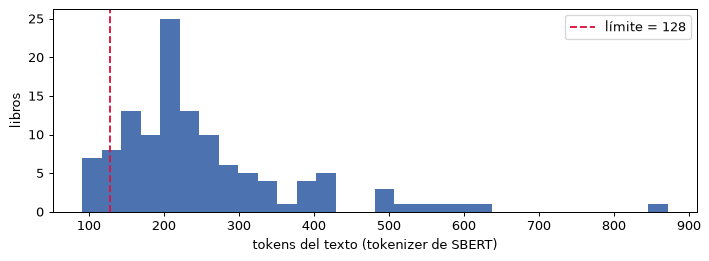

In [12]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(n_tokens, bins=30, color="#4C72B0")
ax.axvline(MAX_TOK, color="crimson", ls="--", label=f"límite = {MAX_TOK}")
ax.set_xlabel("tokens del texto (tokenizer de SBERT)"); ax.set_ylabel("libros"); ax.legend()
plt.tight_layout(); plt.show()

**Lectura.** **109 de 120 libros (91 %) superan el límite** y la mitad de todos los tokens del corpus nunca llega al modelo. En la práctica, SBERT representa cada libro con el título, el autor y las primeras 2 o 3 oraciones de la sinopsis. Eso perjudica a las sinopsis que empiezan con datos editoriales en vez de la trama: la de *David Copperfield* (id 116) dedica sus primeras líneas a la fecha de publicación. La mitigación natural es partir la sinopsis en fragmentos (*chunking*) y guardar varios vectores por libro, que queda como trabajo futuro: elegimos otra parte avanzada.

In [13]:
# La consigna recomienda guardar los embeddings en disco además de en la base
np.save(RAIZ / "embeddings" / "ids.npy", libros.id.to_numpy())
np.save(RAIZ / "embeddings" / "w2v_propio_100.npy", X_w2v)
np.save(RAIZ / "embeddings" / "sbw_promedio_300.npy", X_sbw)
np.save(RAIZ / "embeddings" / "sbert_distiluse_512.npy", X_sbert)
print(sorted(p.name for p in (RAIZ / "embeddings").iterdir()))

['ids.npy', 'sbert_distiluse_512.npy', 'sbw_promedio_300.npy', 'w2v_propio_100.npy']


## D. Comparación y visualización

Cuatro representaciones del mismo texto:
- **TF-IDF** (línea de base léxica del TP1)
- **W2V propio** (promedio, 100D)
- **SBW** (promedio, 300D)
- **SBERT** (512D)

### D.1 Rankings lado a lado

Tres consultas en lenguaje natural que **no** forman parte del benchmark de la sección 5.

In [14]:
tfidf = TfidfVectorizer(preprocessor=normalizar_texto, stop_words=list(STOPWORDS_ES_NORM),
                        token_pattern=r"\b[a-z0-9ñ]{2,}\b", sublinear_tf=True)
X_tfidf = tfidf.fit_transform(libros.texto_crudo)
print("Vocabulario TF-IDF:", len(tfidf.vocabulary_))

def vec_consulta(modelo, consulta):
    if modelo == "TF-IDF":
        return tfidf.transform([consulta])
    if modelo == "W2V propio":
        return vector_documento(tokenizar_w2v(consulta), w2v_propio.wv)
    if modelo == "SBW":
        return vector_documento(tokenizar_w2v(consulta), sbw)
    if modelo == "SBERT":
        return sbert.encode([consulta], normalize_embeddings=True)[0]

MATRICES = {"TF-IDF": X_tfidf, "W2V propio": X_w2v, "SBW": X_sbw, "SBERT": X_sbert}
MODELOS = list(MATRICES)

def similitudes(modelo, consulta):
    q = vec_consulta(modelo, consulta)
    s = MATRICES[modelo] @ (q.T if modelo == "TF-IDF" else q)
    return np.asarray(s.todense()).ravel() if hasattr(s, "todense") else np.asarray(s).ravel()

def ranking(modelo, consulta):
    # Un libro con similitud exactamente 0 no tiene ninguna evidencia a favor: no cuenta como
    # recuperado. Si se lo dejara en la lista, el desempate (orden por id) decidiría el ranking
    # y podría regalar aciertos: en Q12 TF-IDF da 0 a todos y Robin Hood (id 2) quedaba 3.º.
    s = similitudes(modelo, consulta)
    orden = np.argsort(-s, kind="stable")
    return libros.id.to_numpy()[orden[s[orden] != 0]]

TITULO = libros.set_index("id").titulo.str.slice(0, 30)

def lado_a_lado(consulta, k=5):
    tabla = {}
    for m in MODELOS:
        s = similitudes(m, consulta)
        orden = np.argsort(-s, kind="stable")[:k]
        tabla[m] = [f"{TITULO[libros.id[i]]} ({s[i]:.2f})" if s[i] != 0 else "— (similitud 0)" for i in orden]
    return pd.DataFrame(tabla, index=range(1, k + 1))

consultas_demo = [
    "historias de amor imposible entre familias enemigas",
    "un empleado humilde aplastado por la burocracia que pierde la razón",
    "naves espaciales y planetas lejanos",
]
for c in consultas_demo:
    print(f"\n>>> {c}")
    display(lado_a_lado(c))

Vocabulario TF-IDF: 4986

>>> historias de amor imposible entre familias enemigas


,TF-IDF,W2V propio,SBW,SBERT
1,Anna Karénina (Ed. Alba 2010) (0.15),Romeo y Julieta (0.78),Cuentos de amor de locura y de (0.78),Romeo y Julieta (0.37)
2,Romeo y Julieta (0.11),Anna Karénina (Ed. Alba 2010) (0.76),Hermann y Dorotea (0.78),Anna Karénina (Ed. Alba 2010) (0.31)
3,El candor del padre Brown (0.07),Cuentos de amor de locura y de (0.73),Armadale (0.78),Sin nombre (0.26)
4,Botchan (0.07),El salvaje y otros cuentos (0.73),La Señora Lirriper (0.77),"El amor, el dandismo y la intr (0.25)"
5,La dama de las camelias (0.06),Cuentos completos (0.72),Las mil y una noches (0.77),Dafnis y Cloe (0.25)



>>> un empleado humilde aplastado por la burocracia que pierde la razón


,TF-IDF,W2V propio,SBW,SBERT
1,Pequeño hombre ¿y ahora qué? (0.12),El mundo de Guermantes (0.67),El rey Lear (0.79),El doble (0.18)
2,El doble (0.09),El rey Lear (0.64),La taberna (0.78),Las ilusiones perdidas (0.16)
3,El mundo de Guermantes (0.06),Pequeño hombre ¿y ahora qué? (0.64),El hombre de negro (0.78),Hamlet (0.16)
4,Canciones de inocencia y de ex (0.04),Tiempo de silencio (0.62),Pequeño hombre ¿y ahora qué? (0.77),La Venus de las pieles (0.15)
5,Del asesinato considerado como (0.03),Macbeth (0.61),Sin nombre (0.77),El alcalde de Zalamea (0.15)



>>> naves espaciales y planetas lejanos


,TF-IDF,W2V propio,SBW,SBERT
1,— (similitud 0),— (similitud 0),El ciclo de Tschai (0.53),La Venus de las pieles (0.22)
2,— (similitud 0),— (similitud 0),Viaje al Oeste. Las aventuras (0.49),El ciclo de Tschai (0.15)
3,— (similitud 0),— (similitud 0),Narraciones extraordinarias (0.49),Critón (Trad. Gredos) (0.15)
4,— (similitud 0),— (similitud 0),El desierto y otros cuentos (0.49),Electra (0.14)
5,— (similitud 0),— (similitud 0),La tienda de antigüedades (0.49),Los apostólicos (0.12)


**Lectura.**
- **"amor imposible entre familias enemigas":** SBERT y el W2V propio ponen *Romeo y Julieta* primero. TF-IDF lo pone segundo, detrás de *Anna Karénina*, solo por compartir "amor" y "familias". En **SBW los cinco primeros están entre 0,77 y 0,78**: el orden lo decide una diferencia de una centésima (ver D.2).
- **"empleado humilde aplastado por la burocracia":** SBERT encuentra *El doble* (Dostoievski) primero, y TF-IDF también lo recupera porque la sinopsis dice "burocracia". Ninguno trae *El capote* (Gógol), el ejemplo clásico de ese argumento: su sinopsis es una opinión sobre el cuento y no cuenta el argumento.
- **"naves espaciales y planetas lejanos":** TF-IDF y el W2V propio **no tienen ninguna evidencia** (ninguna de esas palabras está en sus vocabularios) y no devuelven nada. SBW encuentra *El ciclo de Tschai*, el único libro de ciencia ficción espacial, gracias a "planeta" ≈ "planetas". SBERT lo pone segundo detrás de *La Venus de las pieles*, con similitudes muy bajas (0,22 contra 0,15): un ranking "prolijo" sobre una señal débil.

### D.2 Distribución de similitudes entre pares al azar

Usamos **todos** los pares de libros distintos (120·119/2 = 7.140). Si en un espacio todo se parece a todo (media alta, desvío chico), el ranking igual devuelve resultados, pero las diferencias entre el primero y el décimo son ruido.

,media,desvío,mín,p5,p95,máx
TF-IDF,0.018,0.034,0.000,0.000,0.047,0.979
W2V propio,0.633,0.077,0.351,0.506,0.753,1.000
SBW,0.887,0.040,0.669,0.809,0.939,1.000
SBERT,0.320,0.104,0.009,0.168,0.485,0.980


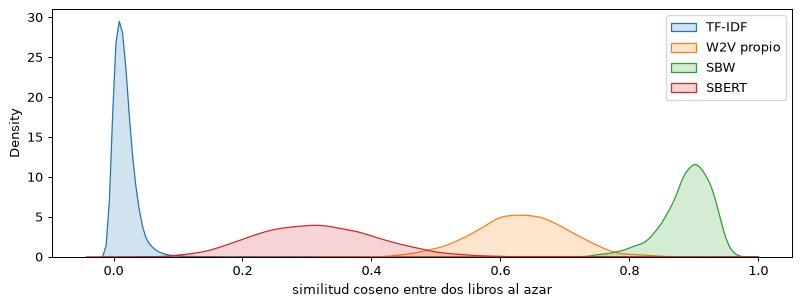

In [15]:
iu = np.triu_indices(N, k=1)
dist = {}
for m in MODELOS:
    M = MATRICES[m]
    S = (M @ M.T).toarray() if hasattr(M, "toarray") else M @ M.T
    dist[m] = S[iu]

def resumen(s):
    return {"media": s.mean(), "desvío": s.std(), "mín": s.min(), "p5": np.percentile(s, 5),
            "p95": np.percentile(s, 95), "máx": s.max()}
tabla_dist = pd.DataFrame({m: resumen(s) for m, s in dist.items()}).T.round(3)
display(tabla_dist)

fig, ax = plt.subplots(figsize=(9, 3.5))
for m, s in dist.items():
    sns.kdeplot(s, ax=ax, label=m, fill=True, alpha=.2, clip=(-0.2, 1))
ax.set_xlabel("similitud coseno entre dos libros al azar"); ax.legend(); plt.tight_layout(); plt.show()

**Lectura.**
- **SBW: todo se parece a todo.** Dos libros al azar tienen similitud media 0,89 con desvío 0,04. Al promediar cientos de vectores de palabra, todos los documentos convergen a la dirección del "texto promedio en español". Por eso en D.1 los top-5 de SBW están separados por centésimas: el ranking existe, pero discrimina poco.
- **El W2V propio** (0,63 ± 0,08) tiene el mismo problema, más suave.
- **SBERT** (0,32 ± 0,10) es el espacio más repartido: es el que más separa libros no relacionados.
- **TF-IDF** (0,02) es casi siempre 0: dos sinopsis casi nunca comparten términos con peso. Discrimina, pero solo cuando hay coincidencia léxica.

**Consecuencia práctica:** los valores absolutos **no se comparan entre modelos**. Un 0,78 en SBW está *por debajo* del promedio de su espacio, y un 0,37 en SBERT está muy por encima del suyo. Cualquier umbral de "relevante si similitud > x" tiene que definirse por modelo.

### D.3 Proyección 2D coloreada por género

Coloreamos por el **primer género** distinto de *Clásico* (los libros tienen varios, así que un solo color ya es una simplificación). Los géneros con menos de 6 libros van a "Otros". Ningún modelo vio los géneros (parte A).

**Advertencias metodológicas**
- **PCA** es lineal y preserva varianza global: informamos la varianza explicada por las dos componentes. Si es baja, una nube mezclada en 2D **no** implica que los géneros estén mezclados en el espacio original.
- **t-SNE** preserva vecindarios locales. Usamos `perplexity = 15`, que es aproximadamente el número de vecinos efectivos que considera cada punto: con 120 libros y grupos de entre 6 y 20 libros, valores de 30 o más juntan todo y valores menores a 5 fragmentan en ruido. En t-SNE **las distancias entre clusters y su tamaño no se interpretan**: el algoritmo expande regiones densas y comprime las ralas.

SBERT: varianza explicada por PC1+PC2 = 13.5%
SBW: varianza explicada por PC1+PC2 = 22.3%


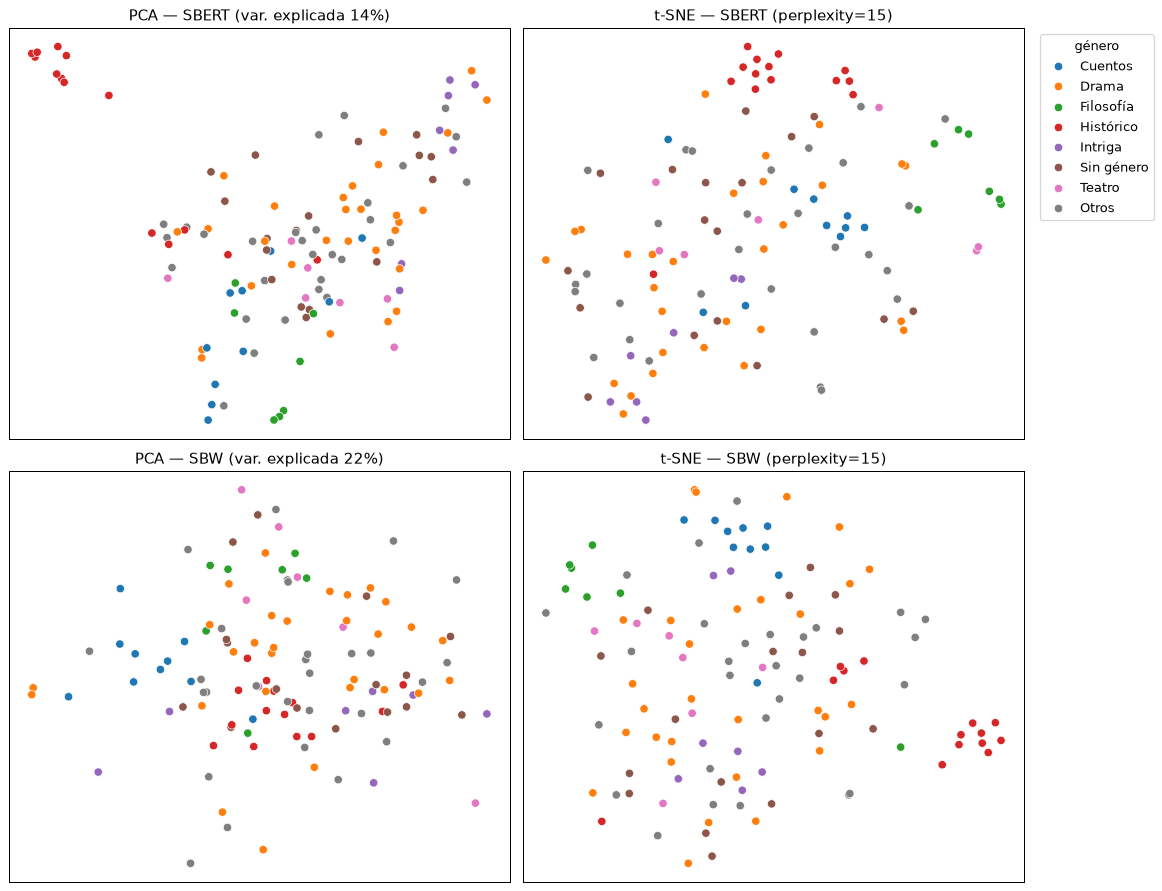

In [16]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

genero_principal = generos_sin_clasico.apply(lambda g: g[0] if g else "Sin género")
frecuentes = genero_principal.value_counts()
genero_color = genero_principal.where(genero_principal.map(frecuentes) >= 6, "Otros")
orden_colores = sorted(genero_color.unique(), key=lambda g: (g == "Otros", g))

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for fila, (m, X) in enumerate([("SBERT", X_sbert), ("SBW", X_sbw)]):
    pca = PCA(n_components=2, random_state=SEED).fit(X)
    P = pca.transform(X)
    T = TSNE(n_components=2, perplexity=15, random_state=SEED, init="pca").fit_transform(X)
    var = pca.explained_variance_ratio_.sum()
    print(f"{m}: varianza explicada por PC1+PC2 = {var:.1%}")
    for col, (Y, titulo) in enumerate([(P, f"PCA — {m} (var. explicada {var:.0%})"),
                                       (T, f"t-SNE — {m} (perplexity=15)")]):
        sns.scatterplot(x=Y[:, 0], y=Y[:, 1], hue=genero_color, hue_order=orden_colores,
                        palette="tab10", s=45, ax=axes[fila, col], legend=(fila == 0 and col == 1))
        axes[fila, col].set_title(titulo); axes[fila, col].set_xticks([]); axes[fila, col].set_yticks([])
axes[0, 1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="género")
plt.tight_layout(); plt.show()

Para no depender solo del dibujo, medimos la separación en el **espacio original**: para cada libro, qué proporción de sus 5 vecinos más cercanos comparte al menos un género (sin contar *Clásico*), comparado con lo que daría el azar.

In [17]:
conjuntos = generos_sin_clasico.apply(set).tolist()
def coherencia_vecinos(X, k=5):
    S = X @ X.T
    np.fill_diagonal(S, -np.inf)
    vec = np.argsort(-S, axis=1)[:, :k]
    return np.mean([np.mean([bool(conjuntos[i] & conjuntos[j]) for j in vec[i]]) for i in range(N)])
azar = np.mean([bool(conjuntos[i] & conjuntos[j]) for i in range(N) for j in range(N) if i != j])
coh = {m: coherencia_vecinos(MATRICES[m].toarray() if m == "TF-IDF" else MATRICES[m]) for m in MODELOS}
coh["azar"] = azar
pd.Series(coh, name="% de 5 vecinos que comparten género").round(3).to_frame()

,% de 5 vecinos que comparten género
TF-IDF,0.397
W2V propio,0.402
SBW,0.355
SBERT,0.347
azar,0.150


**Lectura.**
- Las dos componentes de PCA explican solo el **14 % (SBERT) y el 22 % (SBW)** de la varianza: lo que se ve mezclado en PCA puede no estarlo en el espacio original.
- En SBERT aparecen grupos claros de *Histórico* (Galdós y Baroja), *Filosofía* (sobre todo Platón) y *Cuentos* (Quiroga). *Drama* y *Teatro* quedan dispersos, lo cual es razonable: son etiquetas de forma, no de tema.
- **Cuidado con el grupo *Histórico*:** son casi todos Episodios Nacionales de Galdós, que comparten autor y nombre de serie en el texto. Parte del agrupamiento es "mismo autor", no "mismo género".

La tabla de vecinos lo confirma: en todos los modelos el ~35–40 % de los 5 vecinos de un libro comparte algún género, contra 15 % al azar. **TF-IDF agrupa por género tan bien como SBERT** (0,40 contra 0,35), y la razón es la misma: los libros del mismo autor comparten nombres propios y casi siempre el género. Que un espacio "reconstruya" los géneros no prueba que entienda de qué trata cada libro.

## E. Persistencia e indexado en Postgres (pgvector)

El esquema completo está en `schema_pgvector.sql` y la carga en `src/poblar_supabase.py` (el notebook usa esas mismas funciones):

- **Una tabla por modelo:** `libros_sbw` con `vector(300)` (familia *promedio de word vectors*) y `libros_sbert` con `vector(512)` (familia *modelo de oración*). Dos dimensiones no pueden convivir en la misma columna indexada: `vector(n)` fija la dimensión en el tipo, el índice HNSW compara cada vector con sus vecinos del grafo y necesita que todos vivan en el mismo $\mathbb{R}^n$, y la distancia entre un vector de 300 y uno de 512 no está definida.
- **Índice HNSW con `vector_cosine_ops`:** todas las consultas ordenan por `<=>` (distancia coseno). La opclass tiene que corresponder al operador: un índice `vector_l2_ops` solo acelera `<->`, y con `<=>` el planificador lo ignora y hace un escaneo secuencial.
- **Vectores normalizados y saneados antes de insertar:** se descartan los que tengan NaN/inf o norma 0, se normalizan a norma 1, y además la tabla tiene un `CHECK (vector_norm(embedding) > 0)`.
- **Credenciales fuera del notebook:** la conexión sale de `SUPABASE_DB_URL` (archivo `.env` local, no versionado, o Secretos de Colab). Nunca se imprime.

In [18]:
from poblar_supabase import obtener_db_url, conectar, aplicar_esquema, insertar_embeddings, sanear

conn = conectar(obtener_db_url())
with conn.cursor() as cur:
    cur.execute("SELECT extversion FROM pg_extension WHERE extname = 'vector'")
    print("Conectado. pgvector versión", cur.fetchone()[0])
aplicar_esquema(conn)
print("Esquema aplicado: tablas, índices HNSW (vector_cosine_ops) y funciones SQL.")

# Prueba de la validación con vectores rotos a propósito
prueba = np.vstack([X_sbw[0], np.full(300, np.nan), np.zeros(300), np.r_[X_sbw[1, :299], np.inf]])
print("Validación sobre [vector sano, NaN, cero, inf]:", sanear(prueba, 300)[1].tolist())

for tabla, X, dim in [("libros_sbw", X_sbw, 300), ("libros_sbert", X_sbert, 512)]:
    n, descartados = insertar_embeddings(conn, tabla, libros, X, dim)
    print(f"{tabla}: {n} insertados · descartados por vector inválido: {descartados or 'ninguno'}")

Conectado. pgvector versión 0.8.7
Esquema aplicado: tablas, índices HNSW (vector_cosine_ops) y funciones SQL.
Validación sobre [vector sano, NaN, cero, inf]: [True, False, False, False]
libros_sbw: 120 insertados · descartados por vector inválido: ninguno


libros_sbert: 120 insertados · descartados por vector inválido: ninguno


In [19]:
with conn.cursor() as cur:
    cur.execute('''
        SELECT 'libros_sbw', count(*), min(vector_dims(embedding)), max(vector_dims(embedding)),
               round(min(vector_norm(embedding))::numeric, 4), round(max(vector_norm(embedding))::numeric, 4)
        FROM libros_sbw
        UNION ALL
        SELECT 'libros_sbert', count(*), min(vector_dims(embedding)), max(vector_dims(embedding)),
               round(min(vector_norm(embedding))::numeric, 4), round(max(vector_norm(embedding))::numeric, 4)
        FROM libros_sbert''')
    display(pd.DataFrame(cur.fetchall(), columns=["tabla", "filas", "dim mín", "dim máx", "norma mín", "norma máx"]))
    cur.execute('''SELECT tablename, indexname, indexdef FROM pg_indexes
                   WHERE tablename LIKE 'libros_%' AND indexdef LIKE '%hnsw%' ORDER BY 1''')
    for t, i, d in cur.fetchall():
        print(f"{t}: {d.split('USING ')[1]}")

,tabla,filas,dim mín,dim máx,norma mín,norma máx
0,libros_sbw,120,300,300,1.0000,1.0000
1,libros_sbert,120,512,512,1.0000,1.0000


libros_sbert: hnsw (embedding vector_cosine_ops) WITH (m='16', ef_construction='64')
libros_sbw: hnsw (embedding vector_cosine_ops) WITH (m='16', ef_construction='64')


**¿El índice se usa de verdad?** Con 120 filas el planificador prefiere un escaneo secuencial (leer 120 vectores es más barato que recorrer el grafo), así que para ver el plan desactivamos el escaneo secuencial solo para esta consulta.

In [20]:
q_demo = sbert.encode(["un detective resuelve un crimen"], normalize_embeddings=True)[0]
with conn.cursor() as cur:
    for seqscan in ("on", "off"):
        cur.execute(f"SET enable_seqscan = {seqscan}")
        cur.execute("EXPLAIN SELECT id FROM libros_sbert ORDER BY embedding <=> %s::vector LIMIT 5", (q_demo,))
        # Solo el tipo de cada nodo del plan (el texto completo incluye el vector de 512 valores)
        plan = " → ".join(r[0].strip().lstrip("-> ").split("  (")[0] for r in cur.fetchall()
                          if not r[0].strip().startswith(("Sort Key", "Order By")))
        print(f"enable_seqscan={seqscan}: {plan}")
    cur.execute("RESET enable_seqscan")

enable_seqscan=on: Limit → Sort → Seq Scan on libros_sbert
enable_seqscan=off: Limit → Index Scan using idx_libros_sbert_hnsw on libros_sbert


## F. Búsqueda semántica en SQL

`buscar(consulta, k, genero=None, modelo="sbert")` codifica la consulta en Python (eso es inevitable: Postgres no tiene el modelo) y **toda la similitud, el filtro y el orden se resuelven en SQL** con las funciones `buscar_sbert` / `buscar_sbw` del esquema:

```sql
SELECT l.id, l.titulo, l.generos, 1 - (l.embedding <=> query_vector) AS similitud
FROM libros_sbert l
WHERE filtro_genero IS NULL OR filtro_genero = ANY(l.generos)
ORDER BY l.embedding <=> query_vector
LIMIT top_k;
```

In [21]:
def buscar(consulta, k=5, genero=None, modelo="sbert"):
    if modelo == "sbert":
        q = sbert.encode([consulta], normalize_embeddings=True)[0]
    elif modelo == "sbw":
        q = vector_documento(tokenizar_w2v(consulta), sbw)
        if not np.linalg.norm(q):
            raise ValueError("Ninguna palabra de la consulta está en el vocabulario de SBW")
    else:
        raise ValueError("modelo debe ser 'sbert' o 'sbw'")
    with conn.cursor() as cur:
        cur.execute(f"SELECT * FROM buscar_{modelo}(%s::vector, %s, %s)", (q, k, genero))
        return pd.DataFrame(cur.fetchall(), columns=["id", "titulo", "generos", "similitud"]).round(3)

display(buscar("un asesinato misterioso y un detective brillante", k=5))
display(buscar("un asesinato misterioso y un detective brillante", k=5, genero="Terror"))
display(buscar("un asesinato misterioso y un detective brillante", k=5, genero="Terror", modelo="sbw"))

,id,titulo,generos,similitud
0,54,Del asesinato considerado como una de las bellas artes,"[Clásico, Humor]",0.386
1,14,Sherlock Holmes. La colección completa,"[Clásico, Intriga, Policíaco, Recopilación]",0.325
2,18,El candor del padre Brown,"[Clásico, Policíaco]",0.287
3,4,Armadale,"[Clásico, Intriga]",0.260
4,44,El secreto de Sarah,"[Clásico, Intriga]",0.249


,id,titulo,generos,similitud
0,67,Narraciones extraordinarias,"[Clásico, Terror]",0.235
1,94,Cuentos de amor de locura y de muerte,"[Clásico, Cuentos, Drama, Fantástico, Romántico, Terror]",0.205
2,10,Vampiros (Ilustrado),"[Clásico, Terror]",0.167
3,84,Más allá y otros cuentos,"[Clásico, Cuentos, Drama, Fantástico, Romántico, Terror]",0.077
4,24,El retrato de Dorian Gray,"[Clásico, Terror]",0.066


,id,titulo,generos,similitud
0,24,El retrato de Dorian Gray,"[Clásico, Terror]",0.695
1,10,Vampiros (Ilustrado),"[Clásico, Terror]",0.687
2,94,Cuentos de amor de locura y de muerte,"[Clásico, Cuentos, Drama, Fantástico, Romántico, Terror]",0.677
3,67,Narraciones extraordinarias,"[Clásico, Terror]",0.643
4,84,Más allá y otros cuentos,"[Clásico, Cuentos, Drama, Fantástico, Romántico, Terror]",0.572


### El problema de recall: índice aproximado + filtro selectivo

HNSW no sabe nada del `WHERE`. pgvector recorre el grafo y junta los `ef_search` candidatos más cercanos (40 por defecto) **y recién después** aplica el filtro. Si el género es raro, de esos 40 candidatos quizás ninguno lo cumple, y la consulta devuelve **menos de *k* filas, o ninguna**, aunque en la tabla haya libros de ese género. No es un error visible: simplemente faltan resultados.

Lo forzamos (desactivando el escaneo secuencial, que con 120 filas taparía el problema) y comparamos contra la búsqueda exacta:

In [22]:
SQL_FILTRADA = '''SELECT id FROM libros_sbert WHERE %s = ANY(generos)
                  ORDER BY embedding <=> %s::vector LIMIT 5'''
generos_raros = (generos_sin_clasico.explode().value_counts()
                 .loc[lambda s: (s >= 2) & (s <= 8)].index[:6].tolist())
q_vec = sbert.encode(["una historia de amor y celos en la alta sociedad"], normalize_embeddings=True)[0]
filas = []
with conn.cursor() as cur:
    for g in generos_raros:
        cur.execute("SELECT count(*) FROM libros_sbert WHERE %s = ANY(generos)", (g,))
        total = cur.fetchone()[0]
        cur.execute("SET enable_indexscan = off")          # exacto
        cur.execute(SQL_FILTRADA, (g, q_vec)); exacto = [r[0] for r in cur.fetchall()]
        cur.execute("RESET enable_indexscan")
        cur.execute("SET enable_seqscan = off")            # índice HNSW, ef_search=40
        cur.execute(SQL_FILTRADA, (g, q_vec)); hnsw = [r[0] for r in cur.fetchall()]
        try:
            cur.execute("SET hnsw.iterative_scan = relaxed_order")   # pgvector >= 0.8
            cur.execute(SQL_FILTRADA, (g, q_vec)); iterativo = [r[0] for r in cur.fetchall()]
            cur.execute("RESET hnsw.iterative_scan")
        except Exception:
            conn.rollback(); iterativo = None
        cur.execute("RESET enable_seqscan")
        filas.append({"género": g, "libros del género": total, "exacto (filas)": len(exacto),
                      "HNSW (filas)": len(hnsw), "recall HNSW": len(set(hnsw) & set(exacto)) / len(exacto),
                      "HNSW + iterative_scan (filas)": None if iterativo is None else len(iterativo)})
pd.DataFrame(filas)

,género,libros del género,exacto (filas),HNSW (filas),recall HNSW,HNSW + iterative_scan (filas)
0,Filosofía,7,5,0,0.0,5
1,Aventuras,5,5,2,0.4,5
2,Humor,5,5,2,0.4,5
3,Terror,5,5,3,0.6,5
4,Poesía,5,5,1,0.2,5
5,Ensayo,5,5,2,0.4,5


**Lectura.** Con el índice HNSW y el filtro por género, la consulta pide 5 libros y devuelve **entre 0 y 3**. Con *Filosofía* no devuelve **ninguno**, aunque hay 7 libros de ese género en la tabla. Los 40 candidatos que explora el grafo (`ef_search`) son los más cercanos a la consulta sin mirar el género, y después el filtro los descarta casi a todos.

**Qué haríamos:**
1. **`hnsw.iterative_scan`** (pgvector ≥ 0.8): el índice sigue explorando hasta juntar *k* filas que pasen el filtro. Con `relaxed_order` devuelve los 5 en todos los casos (última columna). Puede devolver el orden levemente alterado, así que conviene re-ordenar por distancia en una consulta externa.
2. **Subir `hnsw.ef_search`** solo en las consultas filtradas (más candidatos a cambio de más costo).
3. **Para filtros muy selectivos, búsqueda exacta sobre el subconjunto filtrado** (índice GIN sobre `generos` y distancia calculada a esas pocas filas). Es lo que hace hoy el planificador con 120 filas: elige el escaneo secuencial y el problema no aparece, pero aparecería al crecer la tabla.
4. Si un filtro es muy frecuente, índices parciales por género.

## 5. Evaluación de los modelos

### 5.1 Conjunto de evaluación (`queries.json`)

12 consultas en lenguaje natural con los libros que consideramos relevantes, anotados leyendo las sinopsis **antes** de mirar resultados. Cuando ampliamos el corpus de 99 a 120 libros revisamos las anotaciones con el mismo criterio (solo leyendo sinopsis): se agregaron libros nuevos relevantes y algunos que faltaban (los cambios quedan documentados en el campo `nota_anotacion`). Q12 está diseñada para **no compartir ninguna palabra** con su documento relevante.

In [23]:
queries = json.load(open(RAIZ / "queries.json", encoding="utf-8"))
REL = {q["id"]: set(q["relevant_ids"]) for q in queries}
TXT = {q["id"]: q["query"] for q in queries}
display(pd.DataFrame([{"id": q["id"], "consulta": q["query"][:70], "tipo": q["tipo"],
                       "relevantes": len(q["relevant_ids"])} for q in queries]))

# Solapamiento léxico: proporción de términos de la consulta (preprocesamiento TF-IDF)
# que aparecen en al menos uno de sus libros relevantes
analizador = tfidf.build_analyzer()
terminos_doc = {i: set(analizador(t)) for i, t in zip(libros.id, libros.texto_crudo)}
def solapamiento(qid):
    tq = set(analizador(TXT[qid]))
    return len(tq & set().union(*(terminos_doc[i] for i in REL[qid]))) / len(tq)
SOLAP = {qid: solapamiento(qid) for qid in REL}
q12 = "Q12_ZERO_OVERLAP"
print("Términos de Q12:", sorted(analizador(TXT[q12])))
print("Términos compartidos con Robin Hood:", sorted(set(analizador(TXT[q12])) & terminos_doc[2]) or "ninguno")

,id,consulta,tipo,relevantes
0,Q01,investigaciones de detectives resolviendo misterios y cr...,semantica_lexica,3
1,Q02,amores contrariados matrimonios de conveniencia y bailes...,semantica_tematica,4
2,Q03,tragedias sobre la ambicion desmedida el asesinato de re...,semantica_tematica,6
3,Q04,episodios de las guerras y conspiraciones politicas en l...,semantica_historica,13
4,Q05,relatos tragicos sobre la locura el delirio y la muerte ...,semantica_tematica,5
5,Q06,dialogos filosoficos sobre la justicia las leyes el esta...,lexica_conceptual,4
6,Q07,brote epidemico contagio colectivo y confinamiento que r...,semantica_abstracta,1
7,Q08,cuentos de terror psicologico tumbas obsesiones morbosas...,semantica_tematica,5
8,Q09,viajes magicos criaturas fabulosas y aventuras epicas or...,semantica_tematica,3
9,Q10,sátiras y comedias teatrales que ridiculizan la hipocres...,semantica_tematica,3


Términos de Q12: ['arquero', 'auxiliar', 'desamparados', 'despoja', 'feudales', 'forajido', 'justiciero', 'tiranos']
Términos compartidos con Robin Hood: ninguno


### 5.2 precision@k con línea de base y piso de azar

$$P@k = \frac{|\{\text{relevantes}\} \cap \{\text{top-}k\}|}{k}$$

Además de los modelos calculamos:
- **Azar (piso):** el valor esperado de P@k eligiendo al azar es $|R_q|/N$ para cada consulta. Lo verificamos simulando 10.000 rankings aleatorios, y de esa simulación sale también el **percentil 95**: un modelo que no supera ese valor no se distingue del azar con 12 consultas.
- **Techo:** la mejor P@k posible es $\min(|R_q|, k)/k$. Q07 y Q12 tienen un solo libro relevante, así que su P@5 máxima es 0,2. Sin el techo, un 0,2 parecería un fracaso.

In [24]:
KS = [1, 3, 5, 10]
def p_at_k(rank, rel, k):
    return len(set(rank[:k]) & rel) / k

RANKINGS = {m: {qid: ranking(m, TXT[qid]) for qid in REL} for m in MODELOS}

def tabla_pk(rankings):
    return {k: np.mean([p_at_k(rankings[qid], REL[qid], k) for qid in REL]) for k in KS}

resultados = {m: tabla_pk(RANKINGS[m]) for m in MODELOS}

rng = np.random.default_rng(SEED)
ids = libros.id.to_numpy()
sim = {k: [] for k in KS}
for _ in range(10_000):
    perm = {qid: rng.permutation(ids) for qid in REL}
    for k in KS:
        sim[k].append(np.mean([p_at_k(perm[qid], REL[qid], k) for qid in REL]))
resultados["Azar (esperado)"] = {k: np.mean([len(REL[q]) / N for q in REL]) for k in KS}
resultados["Azar (simulado, media)"] = {k: np.mean(sim[k]) for k in KS}
resultados["Azar (simulado, p95)"] = {k: np.percentile(sim[k], 95) for k in KS}
resultados["Techo (ideal)"] = {k: np.mean([min(len(REL[q]), k) / k for q in REL]) for k in KS}

tabla = pd.DataFrame(resultados).T
tabla.columns = [f"P@{k}" for k in KS]
tabla.round(3)

,P@1,P@3,P@5,P@10
TF-IDF,0.417,0.278,0.267,0.208
W2V propio,0.333,0.306,0.267,0.200
SBW,0.583,0.389,0.333,0.225
SBERT,0.583,0.472,0.383,0.258
Azar (esperado),0.037,0.037,0.037,0.037
"Azar (simulado, media)",0.036,0.037,0.037,0.037
"Azar (simulado, p95)",0.167,0.083,0.083,0.067
Techo (ideal),1.000,0.889,0.733,0.417


In [25]:
# Detalle por consulta (P@5) con el solapamiento léxico y el techo de cada una
detalle = pd.DataFrame({m: {qid: p_at_k(RANKINGS[m][qid], REL[qid], 5) for qid in REL} for m in MODELOS})
detalle.insert(0, "relevantes", [len(REL[q]) for q in detalle.index])
detalle.insert(1, "solapamiento", [SOLAP[q] for q in detalle.index])
detalle["techo P@5"] = [min(len(REL[q]), 5) / 5 for q in detalle.index]
detalle["azar P@5"] = [len(REL[q]) / N for q in detalle.index]
detalle.round(2)

,relevantes,solapamiento,TF-IDF,W2V propio,SBW,SBERT,techo P@5,azar P@5
Q01,3,0.12,0.2,0.0,0.4,0.6,0.6,0.02
Q02,4,0.00,0.0,0.0,0.2,0.0,0.8,0.03
Q03,6,0.43,0.4,0.6,0.6,0.4,1.0,0.05
Q04,13,0.75,1.0,1.0,1.0,1.0,1.0,0.11
Q05,5,0.43,0.4,0.6,0.2,0.8,1.0,0.04
Q06,4,0.67,0.8,0.2,0.6,0.8,0.8,0.03
Q07,1,0.11,0.2,0.2,0.2,0.2,0.2,0.01
Q08,5,0.12,0.2,0.2,0.4,0.4,1.0,0.04
Q09,3,0.14,0.0,0.4,0.2,0.2,0.6,0.02
Q10,3,0.00,0.0,0.0,0.0,0.0,0.6,0.02


### 5.3 ¿La diferencia con TF-IDF es real o es ruido?

Con 12 consultas, una diferencia de 0,05 en el promedio puede ser casualidad. Usamos un **test de permutación pareado** (por consulta, intercambiamos al azar las etiquetas "modelo" y "TF-IDF"; con 12 consultas son $2^{12} = 4096$ combinaciones, así que el p-valor es exacto) y contamos en cuántas consultas gana, empata o pierde cada modelo.

In [26]:
def test_pareado(m, base="TF-IDF", k=5):
    d = np.array([p_at_k(RANKINGS[m][q], REL[q], k) - p_at_k(RANKINGS[base][q], REL[q], k) for q in REL])
    obs = d.mean()
    signos = np.array(list(itertools.product([1, -1], repeat=len(d))))
    p = np.mean(np.abs((signos * d).mean(axis=1)) >= abs(obs) - 1e-12)
    return {"Δ P@5 vs TF-IDF": obs, "gana": int((d > 0).sum()), "empata": int((d == 0).sum()),
            "pierde": int((d < 0).sum()), "p-valor": p}
comparacion = pd.DataFrame({m: test_pareado(m) for m in MODELOS if m != "TF-IDF"}).T
comparacion.round(3)

,Δ P@5 vs TF-IDF,gana,empata,pierde,p-valor
W2V propio,-0.000,3.0,7.0,2.0,1.000
SBW,0.067,6.0,4.0,2.0,0.289
SBERT,0.117,5.0,7.0,0.0,0.062


In [27]:
# ¿Dónde gana cada familia? Consultas con poco vs. mucho solapamiento léxico con sus relevantes
grupo = pd.cut(detalle.solapamiento, [-0.01, 0.3, 1.0], labels=["solapamiento < 30%", "solapamiento ≥ 30%"])
display(detalle.groupby(grupo, observed=True)[MODELOS].mean().round(3)
        .assign(consultas=detalle.groupby(grupo, observed=True).size()))

def posicion(rk, libro):
    donde = np.where(rk == libro)[0]
    return int(donde[0]) + 1 if len(donde) else "no recuperado"

# Q12: la consulta sin palabras compartidas
print("Q12 — posición de Robin Hood en cada ranking:", {m: posicion(RANKINGS[m][q12], 2) for m in MODELOS})
print("Q12 — libros con similitud > 0 en TF-IDF:", len(RANKINGS["TF-IDF"][q12]),
      "| palabras de Q12 en el vocabulario del W2V propio:",
      [t for t in tokenizar_w2v(TXT[q12]) if t in w2v_propio.wv.key_to_index])
print("Q12 — similitud TF-IDF con Robin Hood:", round(float(similitudes("TF-IDF", TXT[q12])[libros.id == 2][0]), 4))

,TF-IDF,W2V propio,SBW,SBERT,consultas
solapamiento,,,,,
solapamiento < 30%,0.075,0.1,0.2,0.20,8
solapamiento ≥ 30%,0.650,0.6,0.6,0.75,4


Q12 — posición de Robin Hood en cada ranking: {'TF-IDF': 'no recuperado', 'W2V propio': 'no recuperado', 'SBW': 9, 'SBERT': 12}
Q12 — libros con similitud > 0 en TF-IDF: 0 | palabras de Q12 en el vocabulario del W2V propio: []
Q12 — similitud TF-IDF con Robin Hood: 0.0


**Lectura de los resultados**
- **Todos los modelos están muy por encima del azar.** El azar da P@5 = 0,04, y ni siquiera su percentil 95 pasa de 0,08. Pero ninguno se acerca al techo (0,73).
- **SBERT es el mejor:** P@5 = 0,38 contra 0,27 de TF-IDF (+0,12), P@1 = 0,58 contra 0,42. Gana en 5 consultas, empata en 7 y **no pierde en ninguna**.
- **Con 12 consultas la diferencia no es estadísticamente concluyente** (p = 0,06 en el test pareado). SBW (+0,07, p = 0,29) y el W2V propio (±0) no se distinguen de TF-IDF.
- **¿Dónde gana cada familia?** En las 8 consultas con poco solapamiento léxico (< 30 %), TF-IDF casi no acierta (0,08) y los embeddings densos sí (SBW y SBERT 0,20). En las 4 con mucho solapamiento todos andan bien, y TF-IDF (0,65) queda cerca de SBERT (0,75): ahí la coincidencia exacta de palabras es suficiente (Q04 Galdós, Q06 Sócrates).
- **Q12 (sin palabras compartidas):** TF-IDF no recupera nada, como se esperaba por construcción. **Pero tampoco ganan los embeddings:** SBERT pone a Robin Hood 12.º y SBW 9.º. Lo analizamos en 5.5.
- **Q10 (comedias satíricas) da 0 en todos los modelos.**

**Un error que encontramos en nuestra propia evaluación:** en la primera versión, el ranking ordenaba con `argsort` todos los libros, incluso los de similitud 0. En Q12, TF-IDF da 0 a todos los libros y el desempate por id dejaba a Robin Hood (id 2) en el puesto 3, así que TF-IDF "acertaba" Q12 por casualidad (P@5 = 0,2). Ahora un libro con similitud 0 no cuenta como recuperado.

### 5.4 ¿El índice HNSW cambia los resultados?

La evaluación de arriba se calculó en memoria (búsqueda exacta). Verificamos que la búsqueda en Postgres con el índice HNSW devuelve lo mismo para las 12 consultas.

In [28]:
recalls = []
with conn.cursor() as cur:
    cur.execute("SET enable_seqscan = off")
    for qid in REL:
        q = sbert.encode([TXT[qid]], normalize_embeddings=True)[0]
        cur.execute("SELECT id FROM libros_sbert ORDER BY embedding <=> %s::vector LIMIT 10", (q,))
        sql_ids = {r[0] for r in cur.fetchall()}
        recalls.append(len(sql_ids & set(RANKINGS["SBERT"][qid][:10])) / 10)
    cur.execute("RESET enable_seqscan")
print(f"Recall@10 del índice HNSW contra la búsqueda exacta: {np.mean(recalls):.3f}")

Recall@10 del índice HNSW contra la búsqueda exacta: 1.000


### 5.5 Un caso donde la búsqueda falló

In [29]:
def inspeccionar(qid, modelo="SBERT", k=5):
    print(f"{qid}: '{TXT[qid]}'  |  relevantes: {sorted(REL[qid])}")
    rk = RANKINGS[modelo][qid]
    for i, b in enumerate(rk[:k], 1):
        print(f"  {i}. [{b}] {TITULO[b]} {'✔' if b in REL[qid] else '✘'}")
    for r in sorted(REL[qid]):
        fila = libros.set_index("id").loc[r]
        print(f"  relevante [{r}] {TITULO[r]} → posición {posicion(rk, r)} "
              f"| tokens SBERT {fila.tokens_sbert} {'(truncado)' if fila.tokens_sbert > MAX_TOK else ''}")

def texto_visto_por_sbert(libro):
    ids_tok = sbert.tokenizer(libros.set_index("id").loc[libro, "texto_crudo"], truncation=True,
                              max_length=MAX_TOK)["input_ids"]
    return sbert.tokenizer.decode(ids_tok, skip_special_tokens=True)

for qid in ["Q12_ZERO_OVERLAP", "Q02"]:
    inspeccionar(qid); print()

Q12_ZERO_OVERLAP: 'forajido justiciero arquero que despoja a tiranos feudales para auxiliar desamparados'  |  relevantes: [2]
  1. [32] Lisístrata ✘
  2. [39] Las furias ✘
  3. [11] El fulgor y la sangre ✘
  4. [28] Un voluntario realista ✘
  5. [80] El rey Lear ✘
  relevante [2] Robin Hood → posición 12 | tokens SBERT 233 (truncado)

Q02: 'amores contrariados matrimonios de conveniencia y bailes en la alta sociedad inglesa'  |  relevantes: [7, 27, 70, 85]
  1. [101] Romeo y Julieta ✘
  2. [91] Nuestro amigo común ✘
  3. [15] Marido y mujer ✘
  4. [80] El rey Lear ✘
  5. [103] Hermann y Dorotea ✘
  relevante [7] Mansfield Park → posición 37 | tokens SBERT 214 (truncado)
  relevante [27] Persuasión → posición 6 | tokens SBERT 213 (truncado)
  relevante [70] Emma → posición 21 | tokens SBERT 210 (truncado)
  relevante [85] La abadía de Northanger → posición 31 | tokens SBERT 143 (truncado)



**Diagnóstico de Q12.** Probamos hipótesis una por una. Las variantes de la consulta se usan **solo para diagnosticar**: no entran en la métrica (cambiar el benchmark después de ver los resultados sería hacer trampa).

In [30]:
print("1) ¿Truncamiento? Final del texto de Robin Hood que SBERT llega a ver:")
print("   ...", texto_visto_por_sbert(2)[-230:])
print("\n2) ¿Cómo tokeniza SBERT las palabras de Q12?")
for w in ["forajido", "justiciero", "despoja", "desamparados", "arquero", "tiranos"]:
    print(f"   {w:13s} → {sbert.tokenizer.tokenize(w)}")
print("\n3) Misma idea con palabras frecuentes (posición de Robin Hood en SBERT):")
for variante in [TXT[q12], "un bandido que roba a los ricos para darle a los pobres",
                 "un arquero que vive en el bosque y roba a los poderosos"]:
    print(f"   {posicion(ranking('SBERT', variante), 2):>3} ← '{variante}'")

1) ¿Truncamiento? Final del texto de Robin Hood que SBERT llega a ver:
   ... duda si fue un personaje real o legendario. Pero se lo describe como un cazador que vivía en los bosques reales de Sherwood, en Nottinghamshire, y de Barnsdale, en Yorkshire. La obra narrativa que circula hasta nuestros días es de

2) ¿Cómo tokeniza SBERT las palabras de Q12?
   forajido      → ['fora', '##ji', '##do']
   justiciero    → ['just', '##icie', '##ro']
   despoja       → ['des', '##po', '##ja']
   desamparados  → ['desa', '##mpa', '##rados']
   arquero       → ['ar', '##quer', '##o']
   tiranos       → ['tira', '##nos']

3) Misma idea con palabras frecuentes (posición de Robin Hood en SBERT):
    12 ← 'forajido justiciero arquero que despoja a tiranos feudales para auxiliar desamparados'
     1 ← 'un bandido que roba a los ricos para darle a los pobres'
     1 ← 'un arquero que vive en el bosque y roba a los poderosos'


**Caso de falla: Q12, Robin Hood en el puesto 12 de SBERT.** La consulta se diseñó para que TF-IDF no pudiera ganar, y supusimos que un modelo semántico sí lo haría. No pasó.

**Hipótesis y verificación**
1. **¿Truncamiento?** Descartado. La sinopsis de Robin Hood supera el límite, pero la parte que describe al personaje ("robaba a gobernantes… para entregar parte del botín a necesitados") está en lo que SBERT sí ve.
2. **¿Vocabulario?** Confirmado. Para no repetir ninguna palabra de la sinopsis, escribimos la consulta con palabras poco frecuentes: *forajido, justiciero, despoja, desamparados*. El tokenizer de SBERT las parte en pedazos sin significado (`fora ##ji ##do`, `des ##po ##ja`), así que el modelo no tiene una representación sólida de ellas. **La misma idea con palabras comunes** ("un bandido que roba a los ricos para darle a los pobres") **pone a Robin Hood 1.º**, también sin compartir palabras con la sinopsis.

**Conclusión:** Q12 no mide solo "paráfrasis sin solapamiento". También mide **vocabulario raro**, y eso le cuesta a cualquier modelo. Para la próxima, las consultas de este tipo deberían usar sinónimos de uso frecuente.

**Segundo caso, Q02 (Jane Austen):** ningún libro relevante en el top-5 de SBERT. SBERT trae *Romeo y Julieta*, que matchea "amores contrariados". Las sinopsis de Austen no mencionan bailes, matrimonios de conveniencia ni "alta sociedad": nosotros anotamos la relevancia **sabiendo de qué tratan esos libros**, no por lo que dice el texto. Ningún modelo que lea solo la sinopsis puede ganar esa consulta, y la métrica lo cuenta como error del modelo.

## 6. Parte avanzada: búsqueda híbrida con Reciprocal Rank Fusion

Combinamos dos canales **dentro de Postgres** (función `buscar_hibrido_rrf` del esquema):
- **Léxico:** full-text nativo (`to_tsvector` / `ts_rank`) con configuración en español + `unaccent`. `plainto_tsquery` une los términos con AND, y una consulta de diez palabras casi nunca aparece completa en una sinopsis, así que los unimos con OR (`consulta_or`) para que cada término sume al ranking.
- **Semántico:** distancia coseno `<=>` sobre SBERT.

$$\text{RRF}(d) = \frac{1}{k + \text{rank}_{\text{léx}}(d)} + \frac{1}{k + \text{rank}_{\text{sem}}(d)}, \quad k = 60$$

RRF usa solo **posiciones**, no puntajes: `ts_rank` y la similitud coseno están en escalas incomparables, y sumar puntajes obligaría a calibrarlos. Un documento que aparece en un solo canal recibe solo ese término. Medimos si le gana a cada canal por separado con el mismo benchmark.

In [31]:
def ranking_sql(funcion, qid, k=10):
    q = sbert.encode([TXT[qid]], normalize_embeddings=True)[0]
    with conn.cursor() as cur:
        if funcion == "fts":
            cur.execute("SELECT id FROM buscar_fts(%s, %s)", (TXT[qid], k))
        elif funcion == "sbert":
            cur.execute("SELECT id FROM buscar_sbert(%s::vector, %s)", (q, k))
        else:
            cur.execute("SELECT id FROM buscar_hibrido_rrf(%s, %s::vector, %s)", (TXT[qid], q, k))
        return np.array([r[0] for r in cur.fetchall()])

RANK_SQL = {nombre: {qid: ranking_sql(f, qid) for qid in REL}
            for nombre, f in [("FTS Postgres (ts_rank)", "fts"), ("SBERT (SQL)", "sbert"), ("Híbrido RRF", "hibrido")]}
for nombre, rk in RANK_SQL.items():
    RANKINGS[nombre] = rk

hibrida = pd.DataFrame({n: tabla_pk(RANK_SQL[n]) for n in RANK_SQL}).T
hibrida.columns = [f"P@{k}" for k in KS]
hibrida.loc["TF-IDF (TP1)"] = [resultados["TF-IDF"][k] for k in KS]
hibrida.loc["Azar (simulado, p95)"] = [resultados["Azar (simulado, p95)"][k] for k in KS]
display(hibrida.round(3))

print("Documentos devueltos por FTS por consulta:", {q: len(RANK_SQL['FTS Postgres (ts_rank)'][q]) for q in REL})
p5 = pd.DataFrame({n: {q: p_at_k(RANK_SQL[n][q], REL[q], 5) for q in REL} for n in RANK_SQL})
display(p5.round(2).T)
display(pd.DataFrame({m: test_pareado("Híbrido RRF", base=m) for m in ["SBERT (SQL)", "FTS Postgres (ts_rank)"]}).T
        .rename(columns={"Δ P@5 vs TF-IDF": "Δ P@5 (híbrido − canal)"}).round(3))

,P@1,P@3,P@5,P@10
FTS Postgres (ts_rank),0.333,0.361,0.300,0.200
SBERT (SQL),0.583,0.472,0.383,0.258
Híbrido RRF,0.500,0.472,0.350,0.242
TF-IDF (TP1),0.417,0.278,0.267,0.208
"Azar (simulado, p95)",0.167,0.083,0.083,0.067


Documentos devueltos por FTS por consulta: {'Q01': 10, 'Q02': 10, 'Q03': 10, 'Q04': 10, 'Q05': 10, 'Q06': 10, 'Q07': 10, 'Q08': 10, 'Q09': 10, 'Q10': 10, 'Q11': 10, 'Q12_ZERO_OVERLAP': 2}


,Q01,Q02,Q03,Q04,Q05,Q06,Q07,Q08,Q09,Q10,Q11,Q12_ZERO_OVERLAP
FTS Postgres (ts_rank),0.6,0.0,0.6,1.0,0.2,0.6,0.0,0.2,0.2,0.0,0.2,0.0
SBERT (SQL),0.6,0.0,0.4,1.0,0.8,0.8,0.2,0.4,0.2,0.0,0.2,0.0
Híbrido RRF,0.6,0.0,0.6,1.0,0.6,0.8,0.2,0.2,0.2,0.0,0.0,0.0


,Δ P@5 (híbrido − canal),gana,empata,pierde,p-valor
SBERT (SQL),-0.033,1.0,8.0,3.0,0.625
FTS Postgres (ts_rank),0.050,3.0,8.0,1.0,0.500


**Lectura.**
- **La búsqueda híbrida no le gana a SBERT solo:** P@5 = 0,35 contra 0,38. Contra SBERT gana 1 consulta, empata 8 y pierde 3. Sí supera al canal léxico solo (0,30).
- **¿Por qué?** RRF le da el mismo peso a los dos canales, y el léxico es débil justamente en las 8 consultas con poco solapamiento. Ahí mete libros con coincidencias de palabras sueltas en el top-5 y desplaza aciertos de SBERT (Q05: 0,8 → 0,6; Q08: 0,4 → 0,2; Q11: 0,2 → 0). Ayuda solo donde el canal léxico es bueno (Q03: 0,4 → 0,6).
- **El full-text de Postgres funciona algo mejor que TF-IDF** (0,30 contra 0,27), sobre todo por el *stemming*. En Q01 las sinopsis dicen "detective" y "misterioso", y la consulta dice "detectives" y "misterios": el stemmer los une (`detectiv`, `misteri`) y TF-IDF no.

Se podría ajustar el peso de cada canal o el *k* de RRF, pero ajustarlos con estas mismas 12 consultas sería sobreajustar al benchmark. Haría falta un segundo conjunto de consultas para validarlo. **Con los datos que tenemos, la combinación no se justifica.**

In [32]:
# Resultados para el informe
salida = {
    "precision": {m: {f"P@{k}": round(v, 4) for k, v in r.items()} for m, r in resultados.items()},
    "hibrida": hibrida.round(4).to_dict(orient="index"),
    "p5_por_consulta": detalle.round(3).to_dict(orient="index"),
    "comparacion_tfidf": comparacion.round(4).to_dict(orient="index"),
    "distribucion_similitudes": tabla_dist.to_dict(orient="index"),
    "truncados": int(truncados.sum()),
}
json.dump(salida, open(RAIZ / "resultados" / "metricas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
conn.close()
print("Guardado resultados/metricas.json")

Guardado resultados/metricas.json


## Uso de asistentes de IA

Usamos asistentes de IA para escribir y depurar código (carga en pgvector, funciones SQL, gráficos) y para revisar el trabajo contra la consigna, lo que nos ayudó a encontrar errores en versiones intermedias. Las anotaciones de relevancia de `queries.json` las hicimos nosotros leyendo las sinopsis, y todas las cifras del informe salen de las salidas de este notebook.